## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [2]:
# Arial fontがないためこちらで実行
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties, findfont

# 1. SVGのフォント設定（テキストとして保持する設定）
mpl.rcParams['svg.fonttype'] = 'none'

# 2. Arialフォントをシステムから検索して設定
try:
    # Arialを探し、パスを取得
    arial_path = findfont(FontProperties(family='Arial'))
    # FontPropertiesを生成
    arial_font = FontProperties(fname=arial_path)
    # matplotlibに適用
    plt.rcParams['font.family'] = arial_font.get_name()
    print(f"Arialフォントを適用しました: {arial_path}")
except Exception as e:
    print(f"Arialが見つかりません。デフォルトフォントを使用します: {e}")
    plt.rcParams['font.family'] = 'sans-serif'

Arialフォントを適用しました: /System/Library/Fonts/Supplemental/Arial.ttf


In [3]:
meta = pd.read_csv("FCoV1_S_all_seq_final_meta_20260306.tsv", sep="\t")
meta

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI
444,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,186,NaN,USA,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI
445,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,360,NaN,Indonesia,Felis catus,ascites,NaN,04-FEB-2024,NCBI
446,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI


In [ ]:
# partial seqs areund 1058 site were manually obtained from Aliview
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("M1058_all_seq.aa.fasta", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,PQ416775.1,VCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFA...
1,PX315748.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFA...
2,PX315749.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...
3,PX315750.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...
4,PX315751.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMALGSITSAVAVPFA...
...,...,...
362,JQ304388.1,-----------------------YTASLIGGMAMGSITSAVAVPFA...
363,JQ304500.1,---------------------------LIGGMALGSITSAVAVPFA...
364,JQ304330.1,---------------------AMYTASLIGGMAMGSITSTVAVPFA...
365,JQ304361.1,---------------------------LIGGMAMGSITSAVAVPFA...


In [5]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,PQ416775.1,VCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFA...,0
1,PX315748.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFA...,0
2,PX315749.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0
3,PX315750.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0
4,PX315751.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMALGSITSAVAVPFA...,0
...,...,...,...
362,JQ304388.1,-----------------------YTASLIGGMAMGSITSAVAVPFA...,1
363,JQ304500.1,---------------------------LIGGMALGSITSAVAVPFA...,1
364,JQ304330.1,---------------------AMYTASLIGGMAMGSITSTVAVPFA...,0
365,JQ304361.1,---------------------------LIGGMAMGSITSAVAVPFA...,0


In [6]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,VCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFA...,0
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFA...,0
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMALGSITSAVAVPFA...,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,JQ304388.1,FECV,Feline coronavirus,FECV577,taxon:12663,461,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304388.1,-----------------------YTASLIGGMAMGSITSAVAVPFA...,1
363,JQ304500.1,FIPV,Feline coronavirus,FIPV826,taxon:12663,391,NaN,Netherlands,Felis catus,internal organ,NaN,12-JUL-2012,NCBI,JQ304500.1,---------------------------LIGGMALGSITSAVAVPFA...,1
364,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304330.1,---------------------AMYTASLIGGMAMGSITSTVAVPFA...,0
365,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304361.1,---------------------------LIGGMAMGSITSAVAVPFA...,0


In [7]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['biotype'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count,FECV_or_FIPV_encodes
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,VCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFA...,0,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFA...,0,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0,1
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,0,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMALGSITSAVAVPFA...,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
362,JQ304388.1,FECV,Feline coronavirus,FECV577,taxon:12663,461,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304388.1,-----------------------YTASLIGGMAMGSITSAVAVPFA...,1,0
363,JQ304500.1,FIPV,Feline coronavirus,FIPV826,taxon:12663,391,NaN,Netherlands,Felis catus,internal organ,NaN,12-JUL-2012,NCBI,JQ304500.1,---------------------------LIGGMALGSITSAVAVPFA...,1,1
364,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304330.1,---------------------AMYTASLIGGMAMGSITSTVAVPFA...,0,0
365,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI,JQ304361.1,---------------------------LIGGMAMGSITSAVAVPFA...,0,0


In [8]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PQ416775.1,VCAQYYNGIMVLPGVVDGNKMAMYTASLIGGMALGSITSAVAVPFA...,1
1,PX315748.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMAMGAITSAVAVPFA...,1
2,PX315749.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,1
3,PX315750.1,VCAQYYNGIMVLPGVVDANKMAMYTASLIGGMALGSITSAVAVPFA...,1
4,PX315751.1,VCAQYYNGIMVLPGVVDQNKMAMYTASLIGGMALGSITSAVAVPFA...,1
...,...,...,...
362,JQ304388.1,-----------------------YTASLIGGMAMGSITSAVAVPFA...,0
363,JQ304500.1,---------------------------LIGGMALGSITSAVAVPFA...,1
364,JQ304330.1,---------------------AMYTASLIGGMAMGSITSTVAVPFA...,0
365,JQ304361.1,---------------------------LIGGMAMGSITSAVAVPFA...,0


### FECVをconsensusにした上でアミノ酸の性質変化を考慮
consensusの取得はfull_lengthのdatasetで実施済み。切り出したアライメントに合うようにコンセンサスを切り出しgapを1つ追加するなど調整

In [9]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "VCAQYYNGIMVLPGVVDDNKMAMYTASLIGGMAMGSITSAVAVPFAMQVQARLNYVALQTDVLQENQKILANAFNNAIGNITLALGKVSNAITTISDGFNTMASALTKIQSVVNQQGEALSQLTSQLQKNFQAISSSIAEIYNRLEKVEADAQVDRLITGRLAALNAYVSQTLTQYAEVKASRQLAMEKVNECVK-SQSDRYGFCGNGT"

L = len(seqs[0])
OFFSET = 1039

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p

records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # --------------------------------------------------
    # 1) exact mutation test
    # --------------------------------------------------
    for aa in uniq:
        if aa == ref:
            continue

        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)

        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos + OFFSET}{aa}",
            "mutation": f"{ref}{pos + OFFSET}{aa}",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 2) any mutation vs no mutation
    # --------------------------------------------------
    any_mut_mask = (col_valid != ref)
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)

        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos + OFFSET}mut",
            "mutation": f"{ref}{pos + OFFSET}mut",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 3) class changed vs not changed
    # --------------------------------------------------
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)

    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)

        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)

            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos + OFFSET}class_change",
                "mutation": f"{ref}{pos + OFFSET}class_change",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

    # --------------------------------------------------
    # 4) target class specific tests
    # --------------------------------------------------
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue

        target_class_mask = (col_cls2 == target_cls)

        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)

            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos + OFFSET}{target_cls}",
                "mutation": f"{ref}{pos + OFFSET}{target_cls}",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

In [10]:
site_summary

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,any_mutation,8.139240e-58,2.928853e-58,6.342278,1
1,1072,exact_aa,8.139240e-58,6.706649e-58,6.342278,1
2,1133,any_mutation,2.015332e-11,5.439031e-12,4.032369,1
3,1133,class_changed,2.406359e-09,2.277727e-09,29.430253,1
4,1133,exact_aa,2.406359e-09,2.974222e-09,29.430253,3
...,...,...,...,...,...,...
513,1191,class_changed,1.000000e+00,1.000000e+00,0.103846,1
514,1228,any_mutation,1.000000e+00,1.000000e+00,0.101389,1
515,1141,class_changed,1.000000e+00,1.000000e+00,0.060520,1
516,1141,target_class,1.000000e+00,1.000000e+00,0.060520,1


In [11]:
site_summary_overall

,pos,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,8.139240e-58,2.928853e-58,6.342278,2
1,1133,2.015332e-11,5.439031e-12,29.430253,6
2,1056,8.629013e-07,4.140126e-07,26.863150,14
3,1135,9.625287e-05,4.555383e-05,28.158114,13
4,1160,1.780754e-03,7.725501e-04,28.650590,6
...,...,...,...,...,...
133,1154,1.000000e+00,1.000000e+00,0.467410,4
134,1068,1.000000e+00,1.000000e+00,0.434403,4
135,1224,1.000000e+00,1.000000e+00,0.320599,6
136,1089,1.000000e+00,1.000000e+00,0.316670,4


In [12]:
# 1. P値が 0.05 未満のポジションを特定
significant_pos = site_summary[site_summary["min_p_corrected_by_type"] < 0.05]["pos"]

# 2. そのポジションの詳細（検定タイプ含む）を site_summary から抽出
detailed_table = site_summary[site_summary["pos"].isin(significant_pos)].copy()

# 3. 見やすくするために並び替え（P値の小さい順）
detailed_table = detailed_table.sort_values("min_p_corrected_by_type")

detailed_table

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,1072,any_mutation,8.139240e-58,2.928853e-58,6.342278,1
1,1072,exact_aa,8.139240e-58,6.706649e-58,6.342278,1
2,1133,any_mutation,2.015332e-11,5.439031e-12,4.032369,1
3,1133,class_changed,2.406359e-09,2.277727e-09,29.430253,1
4,1133,exact_aa,2.406359e-09,2.974222e-09,29.430253,3
5,1133,target_class,2.406359e-09,3.614245e-09,29.430253,1
6,1056,any_mutation,8.629013e-07,4.140126e-07,2.115209,1
7,1056,class_changed,8.629013e-07,5.445166e-07,2.115209,1
8,1135,class_changed,9.625287e-05,4.555383e-05,3.214287,1
10,1160,class_changed,1.780754e-03,7.725501e-04,28.650590,1


In [13]:
# ピボットテーブル化: 行=pos, 列=test_type, 値=P値
pivot_table = detailed_table.pivot(index="pos", columns="test_type", values="min_p_corrected_by_type")

# 結果を表示
print(pivot_table.head(10))

test_type  any_mutation  class_changed      exact_aa  target_class
pos                                                               
1056       4.140126e-07   5.445166e-07  5.471367e-01  3.601406e-01
1072       2.928853e-58            NaN  6.706649e-58           NaN
1074       2.855649e-02   2.503866e-02  8.718695e-02  6.356922e-02
1078       3.592160e-03   3.315943e-03  6.085042e-01  7.219243e-02
1129       1.334021e-03   3.315943e-03  6.062878e-02  1.840265e-02
1133       5.439031e-12   2.277727e-09  2.974222e-09  3.614245e-09
1135       4.663272e-02   4.555383e-05  8.718695e-02  6.356922e-02
1160       8.810902e-04   7.725501e-04  1.312651e-01  7.975603e-02
1212       3.781819e-03   3.315943e-03  6.062878e-02  2.443808e-02


In [14]:
# mutationの性質(test_type)のカラムでp<0.05 をハイライト
# 背景色を塗る関数を定義
def highlight_low_p(val):
    color = 'yellow' if val < 0.05 else ''
    return f'background-color: {color}'

# スタイルを適用して表示
# .format("{:.10f}") で小数点表記、.applymap でハイライトを適用
styled_table = pivot_table.head(10).style \
    .format("{:.10f}") \
    .applymap(highlight_low_p)

styled_table

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_42436/1010008509.py:11: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(highlight_low_p)


test_type,any_mutation,class_changed,exact_aa,target_class
pos,,,,
1056,0.0000004140,0.0000005445,0.5471367298,0.3601406323
1072,0.0000000000,nan,0.0000000000,nan
1074,0.0285564859,0.0250386579,0.0871869520,0.0635692207
1078,0.0035921605,0.0033159429,0.6085042116,0.0721924298
1129,0.0013340211,0.0033159429,0.0606287765,0.0184026481
1133,0.0000000000,0.0000000023,0.0000000030,0.0000000036
1135,0.0466327182,0.0000455538,0.0871869520,0.0635692207
1160,0.0008810902,0.0007725501,0.1312651279,0.0797560271
1212,0.0037818192,0.0033159429,0.0606287765,0.0244380798


ゲノム座標: 1056
アライメント上のインデックス(0始まり): 17
アライメント上の位置(1始まり): 18


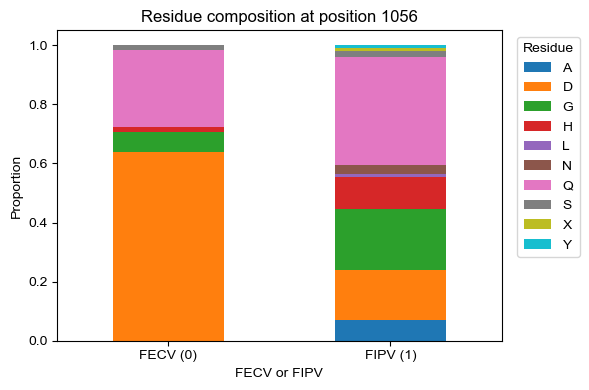

In [65]:
# 表示したいゲノム上の座標
pos = 1056  
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1072
アライメント上のインデックス(0始まり): 33
アライメント上の位置(1始まり): 34


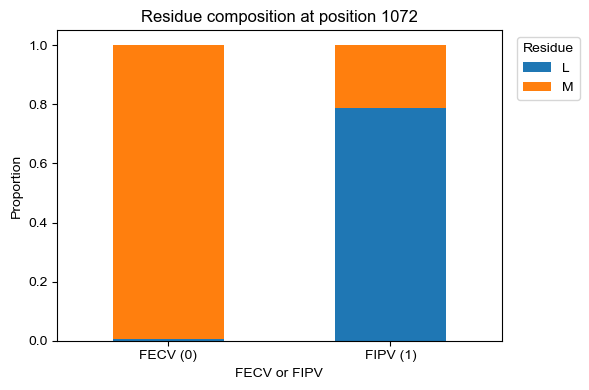

In [66]:
# 表示したいゲノム上の座標
pos = 1072 
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1074
アライメント上のインデックス(0始まり): 35
アライメント上の位置(1始まり): 36


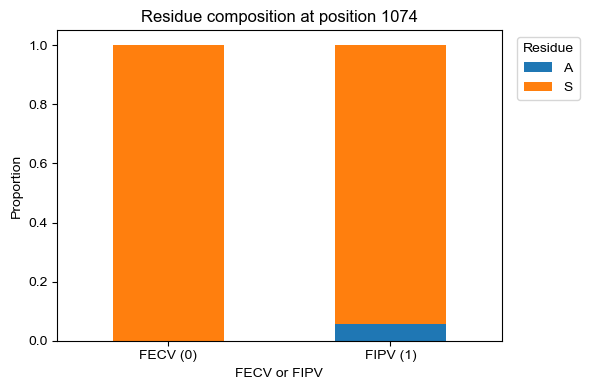

In [81]:
# 表示したいゲノム上の座標
pos = 1074 
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1078
アライメント上のインデックス(0始まり): 39
アライメント上の位置(1始まり): 40


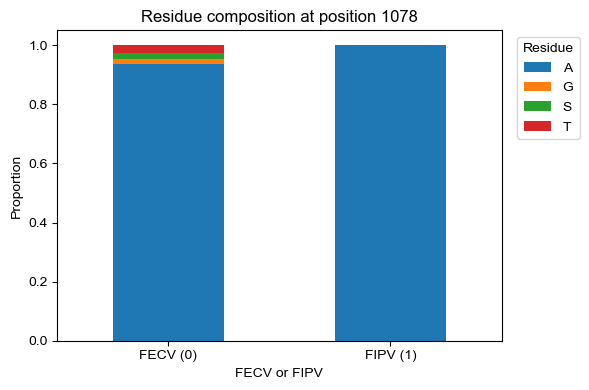

In [80]:
# 表示したいゲノム上の座標
pos = 1078  
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1129
アライメント上のインデックス(0始まり): 90
アライメント上の位置(1始まり): 91


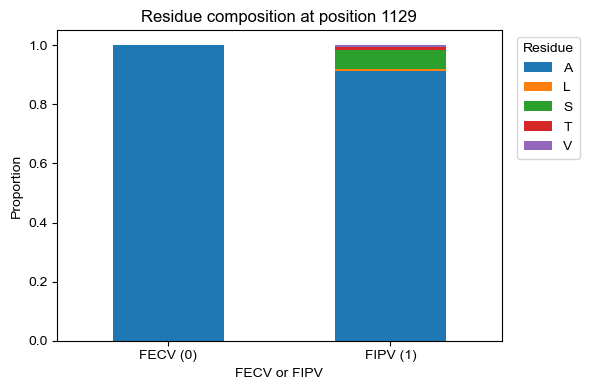

In [79]:
# 表示したいゲノム上の座標
pos = 1129  
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1133
アライメント上のインデックス(0始まり): 94
アライメント上の位置(1始まり): 95


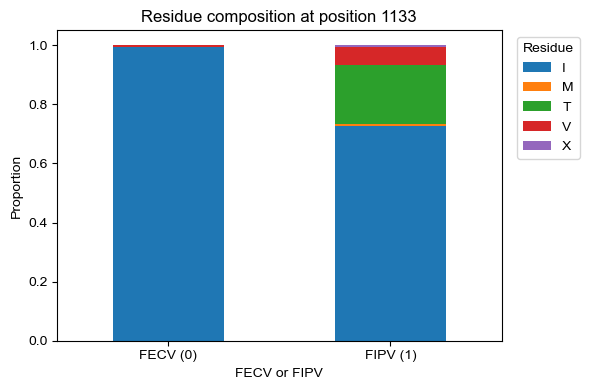

In [78]:
# 表示したいゲノム上の座標
pos = 1133  
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1135
アライメント上のインデックス(0始まり): 96
アライメント上の位置(1始まり): 97


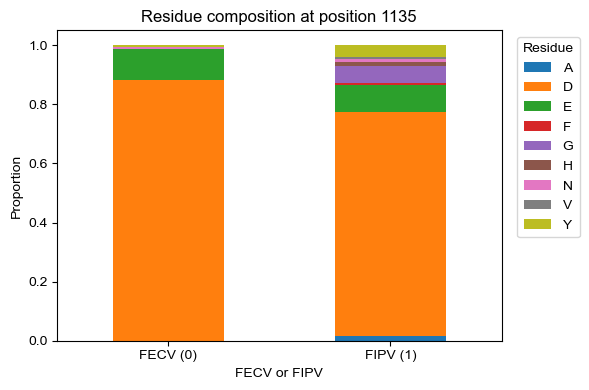

In [77]:
# 表示したいゲノム上の座標
pos = 1135  
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1160
アライメント上のインデックス(0始まり): 121
アライメント上の位置(1始まり): 122


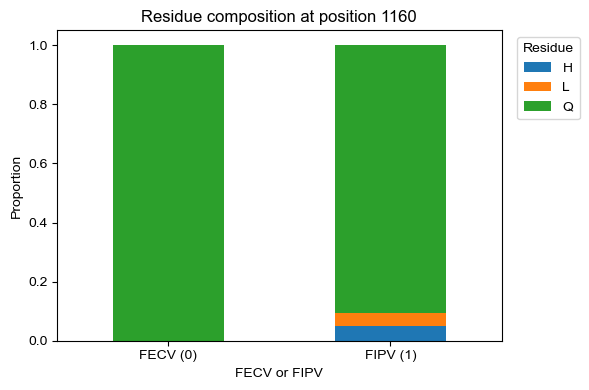

In [76]:
# 表示したいゲノム上の座標
pos = 1160 
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ゲノム座標: 1212
アライメント上のインデックス(0始まり): 173
アライメント上の位置(1始まり): 174


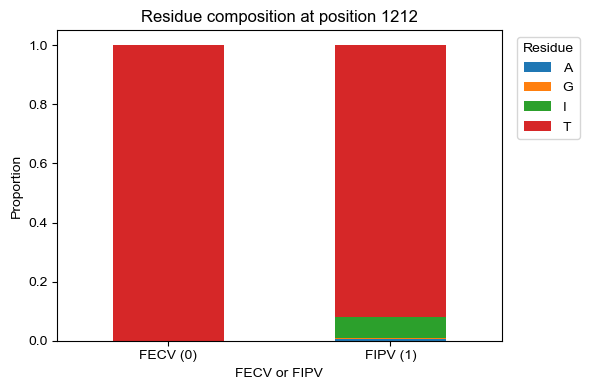

In [75]:
# 表示したいゲノム上の座標
pos = 1212 
# 解析で使用したOFFSET（1039）
offset = 1039

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()